<a href="https://colab.research.google.com/github/Savithmee/Deep-Learning-CW-/blob/Omethmee/EntailmentModelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
!pip install transformers==4.45.2 sentencepiece psutil
import torch, transformers, sentencepiece
print("torch", torch.__version__, "| transformers", transformers.__version__, "| GPU available:", torch.cuda.is_available())
N_FACTS = None   # e.g. 100 for a quick test; None = whole dev set

torch 2.14.1+cu130 | transformers 4.45.2 | GPU available: True


In [30]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR = '/content/drive/MyDrive/data'
LABELS = f'{DATA_DIR}/dev_labeled_ChatGPT.jsonl'
PASSAGES = f'{DATA_DIR}/passages_bm25_ChatGPT_humfacts.jsonl'

print(os.listdir(DATA_DIR))
assert os.path.exists(LABELS) and os.path.exists(PASSAGES), "Files not found - check the file names printed above"
print(LABELS); print(PASSAGES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['FACTSCORE-LICENSE.txt', 'dev_labeled_ChatGPT.jsonl', 'passages_bm25_ChatGPT_humfacts.jsonl']
/content/drive/MyDrive/data/dev_labeled_ChatGPT.jsonl
/content/drive/MyDrive/data/passages_bm25_ChatGPT_humfacts.jsonl


In [31]:
import json, re, gc, time, os
import numpy as np
from typing import List
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

class FactExample(object):
    def __init__(self, fact, passages, label):
        self.fact, self.passages, self.label = fact, passages, label

def read_passages(path):
    d = {}
    with open(path) as f:
        for line in f:
            o = json.loads(line)
            d[o["sent"]] = o["passages"]
    return d

def read_fact_examples(path, fact_to_passage):
    ex = []
    with open(path) as f:
        for line in f:
            o = json.loads(line)
            if o["annotations"] is None: continue
            for sent in o["annotations"]:
                if sent["human-atomic-facts"] is None: continue
                for fact in sent["human-atomic-facts"]:
                    if fact["text"] in fact_to_passage:
                        ex.append(FactExample(fact["text"], fact_to_passage[fact["text"]], fact["label"]))
    return ex

examples = read_fact_examples(LABELS, read_passages(PASSAGES))
if N_FACTS: examples = examples[:N_FACTS]
gold = np.array([1 if (e.label == "S") else 0 for e in examples])   # IR is mapped to NS
print(len(examples), "facts |", gold.sum(), "S /", (1 - gold).sum(), "NS | majority-class accuracy =", round(max(gold.mean(), 1 - gold.mean()), 4))

221 facts | 112 S / 109 NS | majority-class accuracy = 0.5068


In [32]:
# Passage preparation and pruning
import re, html, unicodedata
from typing import List, Dict, Optional

USE_D = True    # False = use the simple stand-ins in Cell 4 instead of this module

STOPWORDS = set("""a about above after again against all am an and any are as at be because been before being
below between both but by can did do does doing down during each few for from further had has have having he her
here hers herself him himself his how i if in into is it its itself just me more most my myself no nor not now of
off on once only or other our ours ourselves out over own same she should so some such than that the their theirs
them themselves then there these they this those through to too under until up very was we were what when where
which while who whom why will with you your yours yourself yourselves also""".split())

DEFAULT_CFG = dict(
    splitter="regex",        # tags | naive | regex | nltk | spacy
    min_words=3,
    max_words=100,
    window=1,                # 1 = single sentences, 2/3 = windows, 10**6 = whole passage
    stride=1,
    title="none",            # none | all | pronoun
    prune_thr=None,          # None = no pruning
    min_keep=1,
    max_keep=None,
    order="window_then_prune",   # or prune_then_window
)

# cleaning (each step can be switched off for the preprocessing experiment; all on = original behaviour)
CLEAN_STEPS = dict(unescape=True, nfkc=True, citations=True, tags=True, whitespace=True, dup_title=True)
_TAG = re.compile(r"<[^>]+>")
_CITE = re.compile(r"\[\d+\]|\[citation needed\]", re.I)

def clean_text(text: str, title: Optional[str] = None) -> str:
    t = text
    if CLEAN_STEPS["unescape"]:
        t = html.unescape(t)
    if CLEAN_STEPS["nfkc"]:
        t = unicodedata.normalize("NFKC", t)
    if CLEAN_STEPS["citations"]:
        t = _CITE.sub(" ", t)
    if CLEAN_STEPS["tags"]:
        t = _TAG.sub(" ", t)
    if CLEAN_STEPS["whitespace"]:
        t = re.sub(r"\s+", " ", t).strip()
    else:
        t = t.strip()
    if CLEAN_STEPS["dup_title"] and title and t.startswith(title + " " + title):
        t = t[len(title) + 1:]
    return t

# sentence splitting
_REGEX_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[\"'(A-Z0-9])")
_SPACY = None
_NLTK_OK = None

def _split_text(segments: List[str], splitter: str) -> List[str]:
    global _SPACY, _NLTK_OK
    if splitter == "tags":
        return segments
    out = []
    if splitter == "naive":
        for s in segments:
            parts = s.split(". ")
            out += [p if p.endswith(".") or i == len(parts) - 1 else p + "." for i, p in enumerate(parts)]
    elif splitter == "regex":
        for s in segments:
            out += _REGEX_SPLIT.split(s)
    elif splitter == "nltk":
        import nltk
        from nltk.tokenize import sent_tokenize
        if _NLTK_OK is None:
            nltk.download("punkt_tab", quiet=True)
            nltk.download("punkt", quiet=True)
            _NLTK_OK = True
        for s in segments:
            out += sent_tokenize(s)
    elif splitter == "spacy":
        if _SPACY is None:
            import spacy
            _SPACY = spacy.blank("en")
            _SPACY.add_pipe("sentencizer")
        for doc in _SPACY.pipe(segments):
            out += [x.text for x in doc.sents]
    else:
        raise ValueError("unknown splitter " + splitter)
    return out

def _chunk(text: str, max_words: Optional[int]) -> List[str]:
    words = text.split()
    if not max_words or len(words) <= max_words:
        return [text]
    pieces, cur = [], []
    for part in re.split(r"(?<=;)\s+", text):
        pw = part.split()
        if cur and len(cur) + len(pw) > max_words:
            pieces.append(" ".join(cur)); cur = []
        cur += pw
    if cur:
        pieces.append(" ".join(cur))
    out = []
    for p in pieces:
        w = p.split()
        out += [" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words)]
    return out

def sentence_units(passages: List[dict], splitter="regex", min_words=3, max_words=100) -> List[Dict]:
    units, seen = [], set()
    for pid, p in enumerate(passages):
        title = p.get("title", "")
        segs = [clean_text(s, title) for s in re.split(r"</?s>", p["text"])]
        segs = [s for s in segs if s]
        sid = 0
        for sent in _split_text(segs, splitter):
            for piece in _chunk(sent.strip(), max_words):
                if len(piece.split()) < min_words:
                    continue
                key = piece.lower()
                if key in seen:
                    continue
                seen.add(key)
                units.append(dict(title=title, pid=pid, sid=sid, text=piece))
                sid += 1
    return units

def _windows(units: List[Dict], window: int, stride: int) -> List[Dict]:
    if window <= 1:
        return [dict(title=u["title"], text=u["text"]) for u in units]
    out, seen = [], set()
    pids = sorted({u["pid"] for u in units})
    for pid in pids:
        g = [u for u in units if u["pid"] == pid]
        n = len(g)
        starts = [0] if window >= n else list(range(0, n - window + 1, max(1, stride)))
        if window < n and starts[-1] != n - window:
            starts.append(n - window)
        for s in starts:
            text = " ".join(u["text"] for u in g[s:s + window])
            if text.lower() not in seen:
                seen.add(text.lower())
                out.append(dict(title=g[0]["title"], text=text))
    return out

def candidates(passages: List[dict], cfg: Optional[dict] = None) -> List[Dict]:
    c = {**DEFAULT_CFG, **(cfg or {})}
    units = sentence_units(passages, c["splitter"], c["min_words"], c["max_words"])
    return _windows(units, c["window"], c["stride"])

# overlap + pruning
def content_tokens(text: str) -> set:
    return {w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOPWORDS}

def overlap_score(fact_tokens: set, text: str) -> float:
    if not fact_tokens:
        return 1.0
    return len(fact_tokens & content_tokens(text)) / len(fact_tokens)

def select(scores: List[float], min_overlap: float, min_keep: int = 1, max_keep: Optional[int] = None) -> List[int]:
    if not scores:
        return []
    keep = [i for i, s in enumerate(scores) if s >= min_overlap]
    if max_keep is not None and len(keep) > max_keep:
        keep = sorted(sorted(keep, key=lambda i: -scores[i])[:max_keep])
    if not keep:
        keep = sorted(sorted(range(len(scores)), key=lambda i: -scores[i])[:max(1, min_keep)])
    return keep

def prune(fact: str, sentences: List[str], min_overlap: float = 0.1,
          min_keep: int = 1, max_keep: Optional[int] = None) -> List[str]:
    ft = content_tokens(fact)
    scores = [overlap_score(ft, s) for s in sentences]
    return [sentences[i] for i in select(scores, min_overlap, min_keep, max_keep)]

# titles + full pipeline
_PRON = re.compile(r"^(He|She|They|His|Her|Their|It|Its)\b")

def _with_title(title: str, text: str, mode: str) -> str:
    if mode == "all" or (mode == "pronoun" and _PRON.match(text)):
        return f"{title}: {text}"
    return text

def make_premises(fact: str, passages: List[dict], cfg: Optional[dict] = None) -> List[Dict]:
    c = {**DEFAULT_CFG, **(cfg or {})}
    ft = content_tokens(fact)
    thr = c["prune_thr"]
    if c["order"] == "prune_then_window" and c["window"] > 1 and thr is not None:
        units = sentence_units(passages, c["splitter"], c["min_words"], c["max_words"])
        sc = [overlap_score(ft, u["text"]) for u in units]
        items, seen = [], set()
        for i in select(sc, thr, c["min_keep"], c["max_keep"]):
            u = units[i]
            grp = [v for v in units if v["pid"] == u["pid"] and u["sid"] <= v["sid"] < u["sid"] + c["window"]]
            plain = " ".join(v["text"] for v in grp)
            if plain.lower() not in seen:
                seen.add(plain.lower())
                items.append(dict(title=u["title"], text=plain))
        cands = items
        scores = [overlap_score(ft, x["text"]) for x in cands]
        keep = list(range(len(cands)))
    else:
        cands = candidates(passages, c)
        scores = [overlap_score(ft, x["text"]) for x in cands]
        keep = list(range(len(cands))) if thr is None else select(scores, thr, c["min_keep"], c["max_keep"])
    return [dict(text=_with_title(cands[i]["title"], cands[i]["text"], c["title"]),
                 plain=cands[i]["text"], overlap=scores[i]) for i in keep]

def split_passages(passages: List[dict], **cfg) -> List[str]:
    c = {**DEFAULT_CFG, **cfg}
    return [_with_title(x["title"], x["text"], c["title"]) for x in candidates(passages, c)]
# end of passage preparation module
print("Passage preparation module loaded | USE_D =", USE_D, "| config:", {k: DEFAULT_CFG[k] for k in ("splitter", "min_words", "max_words", "window", "title")})

Passage preparation module loaded | USE_D = True | config: {'splitter': 'regex', 'min_words': 3, 'max_words': 100, 'window': 1, 'title': 'none'}


In [33]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
CUDA = torch.cuda.is_available()
MODEL_NAME = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
hf_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
if CUDA: hf_model.to("cuda")
hf_model.eval()
print("label order from config:", hf_model.config.id2label)

class EntailmentModel(object):
    def __init__(self, model, tokenizer, cuda=False, max_length=512, cleanup=True):
        self.model, self.tokenizer, self.cuda = model, tokenizer, cuda
        self.max_length, self.cleanup = max_length, cleanup
        id2label = {int(k): v.lower() for k, v in model.config.id2label.items()}
        self.ent_idx = next(i for i, l in id2label.items() if l.startswith("entail"))
        self.neu_idx = next(i for i, l in id2label.items() if l.startswith("neutral"))
        self.con_idx = next(i for i, l in id2label.items() if l.startswith("contra"))

    def check_entailment(self, premise, hypothesis):
        # premise: str or list of str. Returns (n,3) array: [entailment, neutral, contradiction]
        premises = [premise] if isinstance(premise, str) else list(premise)
        with torch.no_grad():
            inputs = self.tokenizer(premises, [hypothesis] * len(premises), return_tensors="pt",
                                    truncation=True, max_length=self.max_length, padding=True)
            if self.cuda:
                inputs = {k: v.to("cuda") for k, v in inputs.items()}
            outputs = self.model(**inputs)
            logits = outputs.logits
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
        probs = probs[:, [self.ent_idx, self.neu_idx, self.con_idx]]
        if self.cleanup:
            del inputs, outputs, logits
            gc.collect()
            if self.cuda: torch.cuda.empty_cache()
        return probs

em = EntailmentModel(hf_model, tokenizer, CUDA)

# ---- simple stand-ins (prefixed sa_ so they never clash with Person D's functions); used only when USE_D = False ----
def sa_clean(t):
    t = re.sub(r"<[^>]+>", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def sa_split(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+|\n+", text) if s.strip()]

def sa_overlap(fact, sentence):
    f = set(re.findall(r"[a-z0-9]+", fact.lower()))
    return len(f & set(re.findall(r"[a-z0-9]+", sentence.lower()))) / len(f) if f else 0.0

# how each input format is built with Person D's module
D_MODES = {
    "sent":       {"window": 1, "title": "none"},       # single sentences
    "window2":    {"window": 2, "title": "none"},       # 2-sentence windows
    "title":      {"window": 1, "title": "all"},        # "Title: sentence"
    "title_pron": {"window": 1, "title": "pronoun"},    # title only on pronoun-led sentences
}
MODES = ["sent", "window2", "title"] + (["title_pron"] if USE_D else [])

def make_units(fact, passages, mode="sent"):
    # returns list of (premise_text, overlap_with_fact); overlap is scored on the plain text, without the title prefix
    if USE_D:
        cfg = {**DEFAULT_CFG, **D_MODES[mode]}
        ft = content_tokens(fact)
        return [(_with_title(x["title"], x["text"], cfg["title"]), overlap_score(ft, x["text"]))
                for x in candidates(passages, cfg)]
    units = []
    for p in passages:
        sents = [sa_clean(s) for s in sa_split(p["text"])]
        sents = [s for s in sents if s]
        if mode == "window2":
            pieces = [sents[0]] if len(sents) == 1 else [sents[i] + " " + sents[i + 1] for i in range(len(sents) - 1)]
        else:
            pieces = sents
        for s in pieces:
            prem = (p["title"] + ": " + s) if mode.startswith("title") else s
            units.append((prem, sa_overlap(fact, s)))
    return units

label order from config: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


In [34]:
def sync():
    if CUDA: torch.cuda.synchronize()

def build_cache(exs, mode="sent", max_length=512, batch=32, desc=""):
    em.max_length = max_length
    cache, pairs = [], 0
    sync(); t0 = time.time()
    for ex in tqdm(exs, desc=desc or mode):
        units = make_units(ex.fact, ex.passages, mode)
        ov = np.array([u[1] for u in units])
        probs = np.zeros((0, 3))
        if units:
            probs = np.concatenate([em.check_entailment([u[0] for u in units[i:i + batch]], ex.fact)
                                    for i in range(0, len(units), batch)])
        pairs += len(units)
        cache.append(dict(ov=ov, probs=probs))
    sync()
    em.max_length = 512
    return dict(cache=cache, seconds=time.time() - t0, pairs=pairs)

caches = {}
caches["sent"] = build_cache(examples, "sent")
print(f"sentence-level pass: {caches['sent']['pairs']} pairs, {caches['sent']['seconds']:.0f}s")

sent:   0%|          | 0/221 [00:00<?, ?it/s]

sentence-level pass: 5242 pairs, 119s


In [35]:
def scores(cache, strategy="p_ent", agg="max", min_ov=0.0, topk=None):
    out = []
    for c in cache:
        idx = np.where(c["ov"] >= min_ov)[0]
        if topk and len(idx) > topk:
            idx = idx[np.argsort(-c["ov"][idx])[:topk]]
        if len(idx) == 0 and USE_D and len(c["ov"]) > 0:
            idx = np.array([int(np.argmax(c["ov"]))])      # same fallback as D's prune: keep the best sentence
        if len(idx) == 0:
            out.append(-np.inf); continue
        p = c["probs"][idx]
        if strategy == "argmax":
            out.append(float((p.argmax(1) == 0).any())); continue
        v = p[:, 0] if strategy == "p_ent" else p[:, 0] - p[:, 2]
        if agg == "max": out.append(v.max())
        elif agg == "top2": out.append(np.sort(v)[-2:].mean())
        elif agg == "mean": out.append(v.mean())
    return np.array(out)

def grid_for(strategy):
    return np.round(np.arange(-1, 1, 0.02), 2) if strategy == "ent_minus_con" else np.round(np.arange(0, 1, 0.01), 2)

def tune(s, strategy, k=5):
    grid = grid_for(strategy)
    accs = np.array([((s > t) == gold).mean() for t in grid])
    sm = np.convolve(accs, np.ones(2 * k + 1) / (2 * k + 1), mode="same")
    idx = np.arange(k, len(grid) - k)
    flat = idx[sm[idx].argmax()]
    return dict(grid=grid, accs=accs, peak_t=grid[accs.argmax()], peak_acc=accs.max(), flat_t=grid[flat], flat_acc=accs[flat])

def f1s(pred, g=None):
    g = gold if g is None else g
    out = []
    for cls in (1, 0):
        tp = ((pred == cls) & (g == cls)).sum(); fp = ((pred == cls) & (g != cls)).sum(); fn = ((pred != cls) & (g == cls)).sum()
        pr = tp / (tp + fp) if tp + fp else 0; rc = tp / (tp + fn) if tp + fn else 0
        out.append(2 * pr * rc / (pr + rc) if pr + rc else 0)
    return out   # [F1_S, F1_NS]

def retention(cache, min_ov, topk=None):
    kept = []
    for c in cache:
        n = (c["ov"] >= min_ov).sum()
        kept.append(min(n, topk) if topk else n)
    kept = np.array(kept)
    return (kept[gold == 1] > 0).mean() * 100, kept.mean(), kept.sum()

In [36]:
C = caches["sent"]["cache"]
rows = []
s = scores(C, "argmax"); pred = (s > 0.5).astype(int)
rows.append(("argmax == entailment", "-", (pred == gold).mean(), *f1s(pred)))
E1 = {}
for st in ["p_ent", "ent_minus_con"]:
    s = scores(C, st); r = tune(s, st); E1[st] = r
    pred = (s > r["flat_t"]).astype(int)
    rows.append((st + " > t (flat t)", r["flat_t"], (pred == gold).mean(), *f1s(pred)))
    rows.append((st + " > t (peak t)", r["peak_t"], r["peak_acc"], *f1s((s > r["peak_t"]).astype(int))))
print(f"{'strategy':<30}{'t':>7}{'acc':>9}{'F1_S':>8}{'F1_NS':>8}")
for n, t, a, fs, fn in rows:
    print(f"{n:<30}{str(t):>7}{a:>9.4f}{fs:>8.4f}{fn:>8.4f}")

strategy                            t      acc    F1_S   F1_NS
argmax == entailment                -   0.8054  0.7943  0.8155
p_ent > t (flat t)               0.71   0.8100  0.7879  0.8279
p_ent > t (peak t)                0.7   0.8145  0.7940  0.8313
ent_minus_con > t (flat t)        0.2   0.8190  0.8165  0.8214
ent_minus_con > t (peak t)        0.2   0.8190  0.8165  0.8214


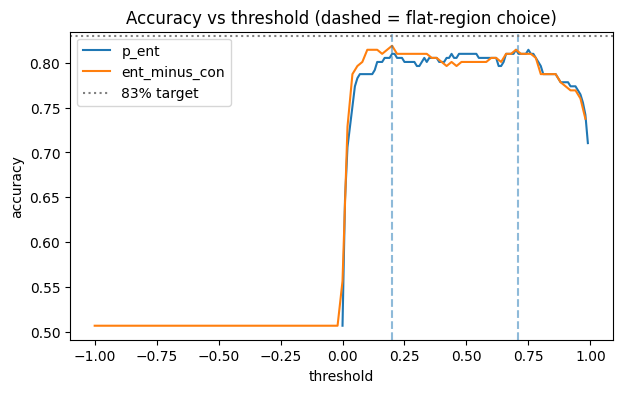

p_ent: 5-fold CV acc = 0.7964 +- 0.0477 | full-dev acc at flat t = 0.8100 | gap = +0.0136
ent_minus_con: 5-fold CV acc = 0.8055 +- 0.0420 | full-dev acc at flat t = 0.8190 | gap = +0.0135


In [37]:
plt.figure(figsize=(7, 4))
for st, r in E1.items():
    plt.plot(r["grid"], r["accs"], label=st)
    plt.axvline(r["flat_t"], ls="--", alpha=.5)
plt.axhline(0.83, color="gray", ls=":", label="83% target")
plt.xlabel("threshold"); plt.ylabel("accuracy"); plt.legend(); plt.title("Accuracy vs threshold (dashed = flat-region choice)")
plt.show()

def cv_gap(strategy, cache, agg="max", min_ov=0.0, folds=5, seed=0):
    s = scores(cache, strategy, agg, min_ov)
    rng = np.random.RandomState(seed); perm = rng.permutation(len(s)); parts = np.array_split(perm, folds)
    grid = grid_for(strategy); accs_cv = []
    for i in range(folds):
        te = parts[i]; tr = np.concatenate([parts[j] for j in range(folds) if j != i])
        a_tr = np.array([((s[tr] > t) == gold[tr]).mean() for t in grid])
        k = 5; sm = np.convolve(a_tr, np.ones(2 * k + 1) / (2 * k + 1), mode="same")
        t_best = grid[k:-k][sm[k:-k].argmax()]
        accs_cv.append(((s[te] > t_best) == gold[te]).mean())
    return np.mean(accs_cv), np.std(accs_cv)

for st in ["p_ent", "ent_minus_con"]:
    m, sd = cv_gap(st, C)
    print(f"{st}: 5-fold CV acc = {m:.4f} +- {sd:.4f} | full-dev acc at flat t = {E1[st]['flat_acc']:.4f} | gap = {E1[st]['flat_acc'] - m:+.4f}")

In [38]:
BEST_STRAT = max(E1, key=lambda k: E1[k]["flat_acc"])
print("strategy carried forward:", BEST_STRAT)
E3 = {}
print(f"{'aggregation':<14}{'flat t':>8}{'acc':>9}")
for agg in ["max", "top2", "mean"]:
    s = scores(C, BEST_STRAT, agg); r = tune(s, BEST_STRAT); E3[agg] = r
    print(f"{agg:<14}{r['flat_t']:>8}{r['flat_acc']:>9.4f}")
BEST_AGG = max(E3, key=lambda k: E3[k]["flat_acc"])
print("aggregation carried forward:", BEST_AGG)

strategy carried forward: ent_minus_con
aggregation     flat t      acc
max                0.2   0.8190
top2              0.14   0.8145
mean              0.04   0.6109
aggregation carried forward: max


In [39]:
for m in MODES:
    if m not in caches:
        caches[m] = build_cache(examples, m)
LABEL_OF = {"sent": "single sentences", "window2": "2-sentence windows",
            "title": "'Title: sentence' (all)", "title_pron": "title on pronoun sentences"}
E45 = {}
print(f"{'input format':<30}{'pairs':>8}{'sec':>7}{'flat t':>8}{'acc':>9}")
for name in MODES:
    r = tune(scores(caches[name]["cache"], BEST_STRAT, BEST_AGG), BEST_STRAT); E45[name] = r
    print(f"{LABEL_OF[name]:<30}{caches[name]['pairs']:>8}{caches[name]['seconds']:>7.0f}{r['flat_t']:>8}{r['flat_acc']:>9.4f}")
BEST_MODE = max(E45, key=lambda k: E45[k]["flat_acc"])
print("input format carried forward:", BEST_MODE)

window2:   0%|          | 0/221 [00:00<?, ?it/s]

title:   0%|          | 0/221 [00:00<?, ?it/s]

title_pron:   0%|          | 0/221 [00:00<?, ?it/s]

input format                     pairs    sec  flat t      acc
single sentences                  5242    119     0.2   0.8190
2-sentence windows                4610    127    0.26   0.8416
'Title: sentence' (all)           5242    112    0.32   0.8190
title on pronoun sentences        5242    109     0.2   0.8235
input format carried forward: window2


In [40]:
caches["sent_128"] = build_cache(examples, "sent", max_length=128, desc="max_length=128")
for name, ml in [("sent_128", 128), ("sent", 512)]:
    r = tune(scores(caches[name]["cache"], BEST_STRAT, BEST_AGG), BEST_STRAT)
    print(f"max_length={ml:<4} acc={r['flat_acc']:.4f}  time={caches[name]['seconds']:.0f}s")

max_length=128:   0%|          | 0/221 [00:00<?, ?it/s]

max_length=128  acc=0.8235  time=107s
max_length=512  acc=0.8190  time=119s


In [41]:
base = caches[BEST_MODE]
cache_b = base["cache"]
sec_per_pair = base["seconds"] / max(base["pairs"], 1)
E7 = []
print(f"{'setting':<14}{'S-retention%':>13}{'sents/fact':>12}{'acc':>9}{'flat t':>8}{'est sec':>9}")
for m in [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]:
    ret, avg, tot = retention(cache_b, m)
    r = tune(scores(cache_b, BEST_STRAT, BEST_AGG, m), BEST_STRAT)
    E7.append(dict(setting=f"ov>={m}", min_ov=m, ret=ret, acc=r["flat_acc"], t=r["flat_t"], est=tot * sec_per_pair))
    print(f"{'ov>='+str(m):<14}{ret:>13.1f}{avg:>12.1f}{r['flat_acc']:>9.4f}{r['flat_t']:>8}{tot*sec_per_pair:>9.0f}")
for k in [3, 5, 10]:
    ret, avg, tot = retention(cache_b, 0.0, k)
    r = tune(scores(cache_b, BEST_STRAT, BEST_AGG, 0.0, k), BEST_STRAT)
    print(f"{'top-'+str(k):<14}{ret:>13.1f}{avg:>12.1f}{r['flat_acc']:>9.4f}{r['flat_t']:>8}{tot*sec_per_pair:>9.0f}")

acc0 = E7[0]["acc"]
ok = [e for e in E7 if e["ret"] >= 98 and e["acc"] >= acc0 - 0.003]
BEST_MINOV = max(ok, key=lambda e: e["min_ov"])["min_ov"]
print("min_overlap carried forward:", BEST_MINOV)

setting        S-retention%  sents/fact      acc  flat t  est sec
ov>=0.0               100.0        20.9   0.8416    0.26      127
ov>=0.05               99.1         9.9   0.8416    0.24       60
ov>=0.1                99.1         9.9   0.8416    0.24       60
ov>=0.15               99.1         9.3   0.8416    0.24       56
ov>=0.2                99.1         8.5   0.8462     0.3       52
ov>=0.3                93.8         5.5   0.8326    0.26       34
ov>=0.4                92.0         3.3   0.8281     0.3       20
ov>=0.5                85.7         2.9   0.8326     0.3       18
top-3                 100.0         3.0   0.8326    0.32       18
top-5                 100.0         5.0   0.8462    0.32       30
top-10                100.0         9.9   0.8371    0.38       60
min_overlap carried forward: 0.2


 batch  sec/fact   peak MB
     1     2.047      1447
     8     0.469      1604
    32     0.327      1745


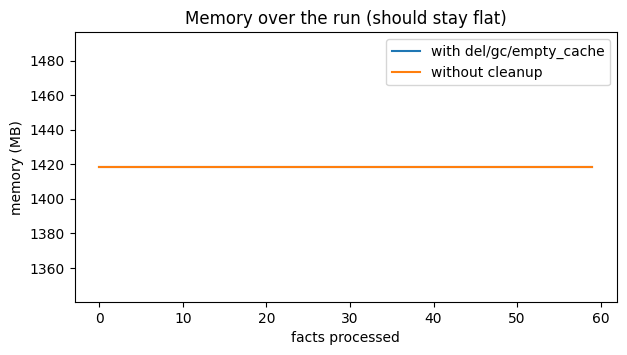

In [42]:
import psutil
def mem_now():
    return torch.cuda.memory_allocated() / 2**20 if CUDA else psutil.Process().memory_info().rss / 2**20

def run_subset(batch, cleanup, n=60, mode=None, min_ov=None):
    mode = mode or BEST_MODE; min_ov = BEST_MINOV if min_ov is None else min_ov
    em.cleanup = cleanup
    if CUDA: torch.cuda.reset_peak_memory_stats()
    trace = []; sync(); t0 = time.time()
    for ex in examples[:n]:
        units = [u for u in make_units(ex.fact, ex.passages, mode) if u[1] >= min_ov]
        for i in range(0, len(units), batch):
            em.check_entailment([u[0] for u in units[i:i + batch]], ex.fact)
        trace.append(mem_now())
    sync()
    peak = torch.cuda.max_memory_allocated() / 2**20 if CUDA else max(trace)
    em.cleanup = True
    return time.time() - t0, peak, trace

n_sub = min(60, len(examples))
print(f"{'batch':>6}{'sec/fact':>10}{'peak MB':>10}")
for b in [1, 8, 32]:
    t, pk, _ = run_subset(b, True, n_sub)
    print(f"{b:>6}{t/n_sub:>10.3f}{pk:>10.0f}")

plt.figure(figsize=(7, 3.5))
for cl in [True, False]:
    _, _, tr = run_subset(32, cl, n_sub)
    plt.plot(tr, label="with del/gc/empty_cache" if cl else "without cleanup")
plt.xlabel("facts processed"); plt.ylabel("memory (MB)"); plt.legend(); plt.title("Memory over the run (should stay flat)")
plt.show()

In [43]:
FULL_ABLATION = False   # True also switches off each cleaning step on its own (more passes, slower)

orig_splitter = DEFAULT_CFG["splitter"]

def run_setting(name, splitter=None, off=()):
    saved = dict(CLEAN_STEPS)
    if splitter:
        DEFAULT_CFG["splitter"] = splitter
    for k in (CLEAN_STEPS if "all" in off else off):
        CLEAN_STEPS[k] = False
    try:
        return build_cache(examples, BEST_MODE, desc=name)
    finally:
        DEFAULT_CFG["splitter"] = orig_splitter
        CLEAN_STEPS.update(saved)

settings = [
    ("final: regex + all cleaning", None, ()),                  # reuses the cache already built
    ("regex, no cleaning at all",   None, ("all",)),
    ("naive split + cleaning",      "naive", ()),
    ("nltk split + cleaning",       "nltk", ()),
    ("no splitting (tags only)",    "tags", ()),
]
if FULL_ABLATION:
    settings += [(f"regex, without '{k}' step", None, (k,)) for k in CLEAN_STEPS]

E8 = {}
print(f"{'preprocessing':<34}{'pairs':>8}{'sents/fact':>12}{'flat t':>8}{'acc':>9}")
for name, sp, off in settings:
    try:
        c = caches[BEST_MODE] if (sp is None and not off) else run_setting(name, sp, off)
    except Exception as ex:
        print(f"{name:<34} skipped: {ex}"); continue
    r = tune(scores(c["cache"], BEST_STRAT, BEST_AGG, BEST_MINOV), BEST_STRAT)
    E8[name] = r
    print(f"{name:<34}{c['pairs']:>8}{retention(c['cache'], BEST_MINOV)[1]:>12.1f}{r['flat_t']:>8}{r['flat_acc']:>9.4f}")

preprocessing                        pairs  sents/fact  flat t      acc
final: regex + all cleaning           4610         8.5     0.3   0.8462


regex, no cleaning at all:   0%|          | 0/221 [00:00<?, ?it/s]

regex, no cleaning at all             4610         8.5     0.3   0.8462


naive split + cleaning:   0%|          | 0/221 [00:00<?, ?it/s]

naive split + cleaning                4790         8.6     0.3   0.8462


nltk split + cleaning:   0%|          | 0/221 [00:00<?, ?it/s]

nltk split + cleaning                 4783         8.6    0.32   0.8462


no splitting (tags only):   0%|          | 0/221 [00:00<?, ?it/s]

no splitting (tags only)              1212         3.5    0.12   0.8009


In [44]:
print("Preprocessing rows for the ablation (same strategy, aggregation, input format and pruning):")
print(f"{'configuration':<36}{'acc':>8}")
for name, r in E8.items():
    print(f"{name:<36}{r['flat_acc']:>8.4f}")

Preprocessing rows for the ablation (same strategy, aggregation, input format and pruning):
configuration                            acc
final: regex + all cleaning           0.8462
regex, no cleaning at all             0.8462
naive split + cleaning                0.8462
nltk split + cleaning                 0.8462
no splitting (tags only)              0.8009


                         pairs  seconds  peak MB
no pruning                4610      114     2035
pruning (0.2)             1881       72     1921
pairs removed: 59% | measured speed-up: 1.58x


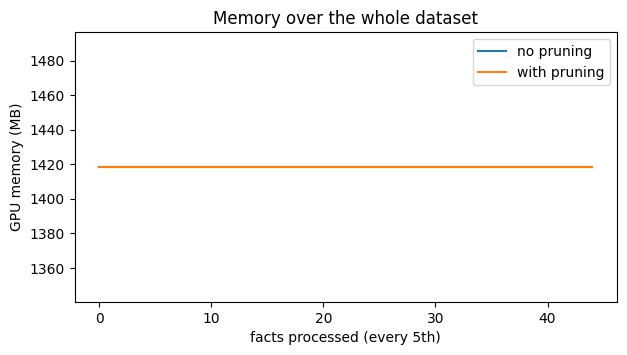

In [45]:
def timed_run(min_ov, batch=32):
    em.cleanup = True
    if CUDA: torch.cuda.reset_peak_memory_stats()
    sync(); t0 = time.time(); pairs = 0; trace = []
    for i, ex in enumerate(examples):
        units = [u for u in make_units(ex.fact, ex.passages, BEST_MODE) if u[1] >= min_ov]
        pairs += len(units)
        for j in range(0, len(units), batch):
            em.check_entailment([u[0] for u in units[j:j + batch]], ex.fact)
        if i % 5 == 0: trace.append(mem_now())
    sync()
    peak = torch.cuda.max_memory_allocated() / 2**20 if CUDA else max(trace)
    return time.time() - t0, pairs, peak, trace

t_no, p_no, pk_no, tr_no = timed_run(0.0)
t_pr, p_pr, pk_pr, tr_pr = timed_run(BEST_MINOV)
print(f"{'':<22}{'pairs':>8}{'seconds':>9}{'peak MB':>9}")
print(f"{'no pruning':<22}{p_no:>8}{t_no:>9.0f}{pk_no:>9.0f}")
print(f"{'pruning (' + str(BEST_MINOV) + ')':<22}{p_pr:>8}{t_pr:>9.0f}{pk_pr:>9.0f}")
print(f"pairs removed: {100*(1-p_pr/p_no):.0f}% | measured speed-up: {t_no/t_pr:.2f}x")

plt.figure(figsize=(7, 3.5))
plt.plot(tr_no, label="no pruning"); plt.plot(tr_pr, label="with pruning")
plt.xlabel("facts processed (every 5th)"); plt.ylabel("GPU memory (MB)"); plt.legend()
plt.title("Memory over the whole dataset"); plt.show()

In [46]:
def row(name, cache_key, strategy, agg, min_ov):
    cc = caches[cache_key]; c = cc["cache"]; spp = cc["seconds"] / max(cc["pairs"], 1)
    s = scores(c, strategy, agg, min_ov)
    if strategy == "argmax":
        pred = (s > 0.5).astype(int); t = "-"
    else:
        r = tune(s, strategy); t = r["flat_t"]; pred = (s > t).astype(int)
    tot = retention(c, min_ov)[2]
    fs, fn = f1s(pred)
    print(f"{name:<44}{(pred == gold).mean():>8.4f}{fs:>8.4f}{fn:>8.4f}{str(t):>7}{tot*spp:>9.0f}")

print(f"{'configuration':<44}{'acc':>8}{'F1_S':>8}{'F1_NS':>8}{'t':>7}{'est sec':>9}")
row("1. argmax, sentences, no pruning", "sent", "argmax", "max", 0.0)
row("2. + " + BEST_STRAT + " with tuned threshold", "sent", BEST_STRAT, "max", 0.0)
row("3. + aggregation: " + BEST_AGG, "sent", BEST_STRAT, BEST_AGG, 0.0)
row("4. + input format: " + BEST_MODE, BEST_MODE, BEST_STRAT, BEST_AGG, 0.0)
row(f"5. + pruning (min_overlap={BEST_MINOV})", BEST_MODE, BEST_STRAT, BEST_AGG, BEST_MINOV)

configuration                                    acc    F1_S   F1_NS      t  est sec
1. argmax, sentences, no pruning              0.8054  0.7943  0.8155      -      119
2. + ent_minus_con with tuned threshold       0.8190  0.8165  0.8214    0.2      119
3. + aggregation: max                         0.8190  0.8165  0.8214    0.2      119
4. + input format: window2                    0.8416  0.8444  0.8387   0.26      127
5. + pruning (min_overlap=0.2)                0.8462  0.8426  0.8496    0.3       52


In [47]:
# ---- Decision cell: review the tables above, then confirm or override each choice ----
OVERRIDE = {}   # e.g. {"BEST_STRAT": "p_ent", "BEST_AGG": "max", "BEST_MODE": "sent", "BEST_MINOV": 0.2}
for k, v in OVERRIDE.items():
    globals()[k] = v

e7 = next((e for e in E7 if e["min_ov"] == BEST_MINOV), None)
print(f"{'decision':<26}{'chosen':<14}{'accuracy':>9}")
print(f"{'decision strategy (E1)':<26}{BEST_STRAT:<14}{E1[BEST_STRAT]['flat_acc']:>9.4f}")
print(f"{'aggregation (E3)':<26}{BEST_AGG:<14}{E3[BEST_AGG]['flat_acc']:>9.4f}")
print(f"{'input format (E4/E5)':<26}{BEST_MODE:<14}{E45[BEST_MODE]['flat_acc']:>9.4f}")
print(f"{'min_overlap pruning (E7)':<26}{str(BEST_MINOV):<14}{(e7['acc'] if e7 else float('nan')):>9.4f}")
print("\nIf you changed the strategy or aggregation, re-run from Cell 9 so the later experiments use it.")

decision                  chosen         accuracy
decision strategy (E1)    ent_minus_con    0.8190
aggregation (E3)          max              0.8190
input format (E4/E5)      window2          0.8416
min_overlap pruning (E7)  0.2              0.8462

If you changed the strategy or aggregation, re-run from Cell 9 so the later experiments use it.


In [48]:
class EntailmentFactChecker(object):
    def __init__(self, ent_model, mode, strategy, agg, threshold, min_overlap, batch=32):
        self.ent_model, self.mode, self.strategy, self.agg = ent_model, mode, strategy, agg
        self.threshold, self.min_overlap, self.batch = threshold, min_overlap, batch

    def predict(self, fact, passages):
        units = make_units(fact, passages, self.mode)
        if not units:
            return "NS"
        if USE_D:
            keep = select([u[1] for u in units], self.min_overlap)      # Person D's pruning rule (keeps the best one if none pass)
        else:
            keep = [i for i, u in enumerate(units) if u[1] >= self.min_overlap]
        units = [units[i] for i in keep]
        if not units:
            return "NS"
        probs = np.concatenate([self.ent_model.check_entailment([u[0] for u in units[i:i + self.batch]], fact)
                                for i in range(0, len(units), self.batch)])
        if self.strategy == "argmax":
            return "S" if (probs.argmax(1) == 0).any() else "NS"
        v = probs[:, 0] if self.strategy == "p_ent" else probs[:, 0] - probs[:, 2]
        score = v.max() if self.agg == "max" else np.sort(v)[-2:].mean() if self.agg == "top2" else v.mean()
        return "S" if score > self.threshold else "NS"

final_t = tune(scores(caches[BEST_MODE]["cache"], BEST_STRAT, BEST_AGG, BEST_MINOV), BEST_STRAT)["flat_t"]
print(dict(mode=BEST_MODE, strategy=BEST_STRAT, agg=BEST_AGG, threshold=final_t, min_overlap=BEST_MINOV, use_d=USE_D))
fc = EntailmentFactChecker(em, BEST_MODE, BEST_STRAT, BEST_AGG, final_t, BEST_MINOV)

conf = [[0, 0], [0, 0]]; idx = ["S", "NS"]; t0 = time.time(); fp_ex, fn_ex = [], []
for ex in tqdm(examples, desc="final run"):
    g = "S" if ex.label == "S" else "NS"
    p = fc.predict(ex.fact, ex.passages)
    conf[idx.index(g)][idx.index(p)] += 1
    if g == "NS" and p == "S": fp_ex.append(ex)
    if g == "S" and p == "NS": fn_ex.append(ex)
acc = (conf[0][0] + conf[1][1]) / len(examples)
print("confusion [gold x pred] (S, NS):", conf)
print(f"FINAL accuracy = {acc:.4f}  ({'meets' if acc >= 0.83 else 'BELOW'} the 83% target) | time {time.time()-t0:.0f}s")
print(len(fp_ex), "false positives,", len(fn_ex), "false negatives (for the error analysis)")

{'mode': 'window2', 'strategy': 'ent_minus_con', 'agg': 'max', 'threshold': np.float64(0.3), 'min_overlap': 0.2, 'use_d': True}


final run:   0%|          | 0/221 [00:00<?, ?it/s]

confusion [gold x pred] (S, NS): [[91, 21], [13, 96]]
FINAL accuracy = 0.8462  (meets the 83% target) | time 87s
13 false positives, 21 false negatives (for the error analysis)


            pred S  pred NS
true S          91       21
true NS         13       96

accuracy = 187/221 = 0.8462
 S: precision 0.875 | recall 0.812 | F1 0.843
NS: precision 0.821 | recall 0.881 | F1 0.850


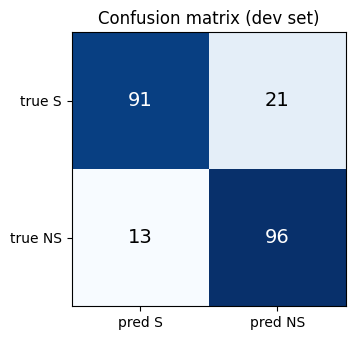

In [49]:
import numpy as np
import matplotlib.pyplot as plt

cm = np.array(conf)          # rows = true label (S, NS), columns = predicted label (S, NS)
labels = ["S", "NS"]

# table
print(f"{'':<10}{'pred S':>8}{'pred NS':>9}")
for i, name in enumerate(labels):
    print(f"{'true ' + name:<10}{cm[i, 0]:>8}{cm[i, 1]:>9}")
print(f"\naccuracy = {np.trace(cm)}/{cm.sum()} = {np.trace(cm) / cm.sum():.4f}")

# per-class precision, recall and F1
for i, name in enumerate(labels):
    tp = cm[i, i]
    prec = tp / cm[:, i].sum()
    rec = tp / cm[i, :].sum()
    f1 = 2 * prec * rec / (prec + rec)
    print(f"{name:>2}: precision {prec:.3f} | recall {rec:.3f} | F1 {f1:.3f}")

# heatmap (saved as a picture for the report)
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["pred S", "pred NS"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["true S", "true NS"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
ax.set_title("Confusion matrix (dev set)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

In [50]:
import random

def explain(ex, tag):
    units = make_units(ex.fact, ex.passages, BEST_MODE)
    if not units:
        print(f"[{tag}] gold={ex.label} | FACT: {ex.fact} | no premises found\n"); return
    units = [units[i] for i in select([u[1] for u in units], BEST_MINOV)]
    probs = np.concatenate([em.check_entailment([u[0] for u in units[i:i + 32]], ex.fact)
                            for i in range(0, len(units), 32)])
    s = probs[:, 0] - probs[:, 2] if BEST_STRAT == "ent_minus_con" else probs[:, 0]
    b = int(np.argmax(s))
    print(f"[{tag}] gold label: {ex.label} | score {s[b]:.2f} (threshold {float(final_t):.2f}) | "
          f"P(ent)={probs[b,0]:.2f} P(neu)={probs[b,1]:.2f} P(con)={probs[b,2]:.2f}")
    print("  FACT:          ", ex.fact)
    print("  BEST PREMISE:  ", units[b][0][:350])
    print("  premises scored:", len(units), "\n")

rng = random.Random(0)
print("=" * 12, "FALSE POSITIVES (gold NS, predicted S)")
for i, ex in enumerate(rng.sample(fp_ex, min(10, len(fp_ex))), 1):
    explain(ex, f"FP{i}")
print("=" * 12, "FALSE NEGATIVES (gold S, predicted NS)")
for i, ex in enumerate(rng.sample(fn_ex, min(10, len(fn_ex))), 1):
    explain(ex, f"FN{i}")

============ FALSE POSITIVES (gold NS, predicted S)
[FP1] gold label: NS | score 0.87 (threshold 0.30) | P(ent)=0.87 P(neu)=0.13 P(con)=0.00
  FACT:           She has worked with a number of organizations.
  BEST PREMISE:   She currently resides in Walthamstow, London, where she worked as a mediator and a regular FGM educator for Waltham Forest Borough. Her testimonials and campaigning work have made her one of Britain's most prominent campaigners about FGM and she has appeared in numerous publications, including the "Telegraph", the BBC, and "The Guardian".
  premises scored: 4 

[FP2] gold label: NS | score 0.99 (threshold 0.30) | P(ent)=0.99 P(neu)=0.01 P(con)=0.00
  FACT:           Kerser is a songwriter.
  BEST PREMISE:   Kerser's fourth album "King", produced by Nebs, was released on 14 November 2014. His fifth album titled "Next Step" was released on 13 November 2015 and produced by Sinima Beats.
  premises scored: 16 

[FP3] gold label: NS | score 0.96 (threshold 0.30) | P(ent)

In [51]:
tp, fn = conf[0]   # gold S:  predicted S, predicted NS
fp, tn = conf[1]   # gold NS: predicted S, predicted NS
total = tp + fn + fp + tn

print(f"True positives  (gold S,  predicted S):  {tp}")
print(f"True negatives  (gold NS, predicted NS): {tn}")
print(f"False positives (gold NS, predicted S):  {fp}")
print(f"False negatives (gold S,  predicted NS): {fn}")
print(f"Total errors: {fp + fn} of {total} ({100 * (fp + fn) / total:.1f}%)")
print(f"Accuracy: {tp + tn}/{total} = {(tp + tn) / total:.4f}")

# cross-check against the lists of error examples
assert fp == len(fp_ex) and fn == len(fn_ex), "counts do not match the error lists"

True positives  (gold S,  predicted S):  91
True negatives  (gold NS, predicted NS): 96
False positives (gold NS, predicted S):  13
False negatives (gold S,  predicted NS): 21
Total errors: 34 of 221 (15.4%)
Accuracy: 187/221 = 0.8462


In [52]:
!pip -q install python-docx

import random
from docx import Document
from docx.shared import Pt, Cm
from google.colab import files

SAMPLE_ONLY = True    # True = the same 10 + 10 random errors as the error-reading cell; False = every error
TOP_K = 3             # how many top-scoring premises to list for each error

def error_record(ex, predicted):
    units = make_units(ex.fact, ex.passages, BEST_MODE)
    units = [units[i] for i in select([u[1] for u in units], BEST_MINOV)] if units else []
    if not units:
        return dict(fact=ex.fact, gold=ex.label, pred=predicted, score=None, probs=None, premises=[], n=0)
    probs = np.concatenate([em.check_entailment([u[0] for u in units[i:i + 32]], ex.fact)
                            for i in range(0, len(units), 32)])
    s = probs[:, 0] - probs[:, 2] if BEST_STRAT == "ent_minus_con" else probs[:, 0]
    order = np.argsort(-s, kind="stable")[:TOP_K]
    b = int(order[0])
    return dict(fact=ex.fact, gold=ex.label, pred=predicted, score=float(s[b]),
                probs=tuple(float(x) for x in probs[b]), n=len(units),
                premises=[(units[i][0], float(s[i])) for i in order])

def add_row(table, label, text):
    cells = table.add_row().cells
    cells[0].text = label
    cells[1].text = text
    if cells[0].paragraphs[0].runs:
        cells[0].paragraphs[0].runs[0].bold = True

def add_section(doc, title, errors, prefix, predicted):
    doc.add_heading(title, 1)
    for i, ex in enumerate(errors, 1):
        r = error_record(ex, predicted)
        doc.add_heading(f"{prefix}{i}", 2)
        t = doc.add_table(rows=0, cols=2)
        t.style = "Table Grid"
        gold = r["gold"] + (" (counted as NS)" if r["gold"] == "IR" else "")
        add_row(t, "Fact", r["fact"])
        add_row(t, "Gold label", gold)
        add_row(t, "Model prediction", r["pred"])
        if r["score"] is None:
            add_row(t, "Score", "no premise left after pruning")
        else:
            add_row(t, "Score", f"{r['score']:.2f} (threshold {float(final_t):.2f})")
            add_row(t, "P(entail) / P(neutral) / P(contradict)", " / ".join(f"{x:.2f}" for x in r["probs"]))
        add_row(t, "Premises scored", str(r["n"]))
        for k, (prem, sc) in enumerate(r["premises"], 1):
            add_row(t, f"Premise {k} (score {sc:.2f})", prem)
        add_row(t, "Your notes: why did the model get this wrong?", "\n\n")
        add_row(t, "Category (your own)", "")
        for row in t.rows:
            row.cells[0].width = Cm(4.5)
            row.cells[1].width = Cm(12)

if SAMPLE_ONLY:
    rng = random.Random(0)                                   # same seed and order as the error-reading cell
    fps = rng.sample(fp_ex, min(10, len(fp_ex)))
    fns = rng.sample(fn_ex, min(10, len(fn_ex)))
else:
    fps, fns = list(fp_ex), list(fn_ex)

doc = Document()
doc.styles["Normal"].font.size = Pt(10)
doc.add_heading("Error analysis worksheet", 0)
doc.add_paragraph(f"Dev set: {len(examples)} facts. Decision rule: {BEST_STRAT}, threshold {float(final_t):.2f}, "
                  f"input format {BEST_MODE}, min_overlap {BEST_MINOV}.")
doc.add_paragraph(f"False positives in total: {len(fp_ex)}. False negatives in total: {len(fn_ex)}. "
                  f"Listed here: {len(fps)} false positives and {len(fns)} false negatives.")
doc.add_paragraph("Gold label IR is counted as NS in the evaluation.")

add_section(doc, "False positives (gold NS, predicted S)", fps, "FP", "S")
add_section(doc, "False negatives (gold S, predicted NS)", fns, "FN", "NS")

doc.save("10_error_analysis.docx")
files.download("10_error_analysis.docx")
print("saved 10_error_analysis.docx:", len(fps), "false positives and", len(fns), "false negatives")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved 10_error_analysis.docx: 10 false positives and 10 false negatives


In [53]:
!pip -q install python-docx

import random
from docx import Document
from docx.shared import Pt, Cm
from google.colab import files

SAMPLE_ONLY = False    # True = the same 10 + 10 random errors as the error-reading cell; False = every error
TOP_K = 3             # how many top-scoring premises to list for each error

def error_record(ex, predicted):
    units = make_units(ex.fact, ex.passages, BEST_MODE)
    units = [units[i] for i in select([u[1] for u in units], BEST_MINOV)] if units else []
    if not units:
        return dict(fact=ex.fact, gold=ex.label, pred=predicted, score=None, probs=None, premises=[], n=0)
    probs = np.concatenate([em.check_entailment([u[0] for u in units[i:i + 32]], ex.fact)
                            for i in range(0, len(units), 32)])
    s = probs[:, 0] - probs[:, 2] if BEST_STRAT == "ent_minus_con" else probs[:, 0]
    order = np.argsort(-s, kind="stable")[:TOP_K]
    b = int(order[0])
    return dict(fact=ex.fact, gold=ex.label, pred=predicted, score=float(s[b]),
                probs=tuple(float(x) for x in probs[b]), n=len(units),
                premises=[(units[i][0], float(s[i])) for i in order])

def add_row(table, label, text):
    cells = table.add_row().cells
    cells[0].text = label
    cells[1].text = text
    if cells[0].paragraphs[0].runs:
        cells[0].paragraphs[0].runs[0].bold = True

def add_section(doc, title, errors, prefix, predicted):
    doc.add_heading(title, 1)
    for i, ex in enumerate(errors, 1):
        r = error_record(ex, predicted)
        doc.add_heading(f"{prefix}{i}", 2)
        t = doc.add_table(rows=0, cols=2)
        t.style = "Table Grid"
        gold = r["gold"] + (" (counted as NS)" if r["gold"] == "IR" else "")
        add_row(t, "Fact", r["fact"])
        add_row(t, "Gold label", gold)
        add_row(t, "Model prediction", r["pred"])
        if r["score"] is None:
            add_row(t, "Score", "no premise left after pruning")
        else:
            add_row(t, "Score", f"{r['score']:.2f} (threshold {float(final_t):.2f})")
            add_row(t, "P(entail) / P(neutral) / P(contradict)", " / ".join(f"{x:.2f}" for x in r["probs"]))
        add_row(t, "Premises scored", str(r["n"]))
        for k, (prem, sc) in enumerate(r["premises"], 1):
            add_row(t, f"Premise {k} (score {sc:.2f})", prem)
        add_row(t, "Your notes: why did the model get this wrong?", "\n\n")
        add_row(t, "Category (your own)", "")
        for row in t.rows:
            row.cells[0].width = Cm(4.5)
            row.cells[1].width = Cm(12)

if SAMPLE_ONLY:
    rng = random.Random(0)                                   # same seed and order as the error-reading cell
    fps = rng.sample(fp_ex, min(10, len(fp_ex)))
    fns = rng.sample(fn_ex, min(10, len(fn_ex)))
else:
    fps, fns = list(fp_ex), list(fn_ex)

doc = Document()
doc.styles["Normal"].font.size = Pt(10)
doc.add_heading("Error analysis worksheet", 0)
doc.add_paragraph(f"Dev set: {len(examples)} facts. Decision rule: {BEST_STRAT}, threshold {float(final_t):.2f}, "
                  f"input format {BEST_MODE}, min_overlap {BEST_MINOV}.")
doc.add_paragraph(f"False positives in total: {len(fp_ex)}. False negatives in total: {len(fn_ex)}. "
                  f"Listed here: {len(fps)} false positives and {len(fns)} false negatives.")
doc.add_paragraph("Gold label IR is counted as NS in the evaluation.")

add_section(doc, "False positives (gold NS, predicted S)", fps, "FP", "S")
add_section(doc, "False negatives (gold S, predicted NS)", fns, "FN", "NS")

doc.save("34_error_analysis.docx")
files.download("34_error_analysis.docx")
print("saved 34_error_analysis.docx:", len(fps), "false positives and", len(fns), "false negatives")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved 34_error_analysis.docx: 13 false positives and 21 false negatives
